# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [15]:
import os
from scipy.spatial.distance import cdist

def load(i):
    for ext in ('.xls', '.xlsx'):
        if os.path.exists(f'{i}{ext}'):
            d = pd.read_excel(f'{i}{ext}', header=None)
            break
    if not np.issubdtype(d[0].dtype, np.number):
        d = d.iloc[1:]
    return d.astype(float).values

data = [load(i) for i in range(6)]
metrics = ['euclidean', 'euclidean', 'cityblock', 'cityblock', 'euclidean', 'euclidean']
for i, P in enumerate(data):
    print(f'задача {i+1}: {P.shape[0]} точек, метрика {metrics[i]}')

задача 1: 100 точек, метрика euclidean
задача 2: 9999 точек, метрика euclidean
задача 3: 1000 точек, метрика cityblock
задача 4: 10000 точек, метрика cityblock
задача 5: 500 точек, метрика euclidean
задача 6: 9999 точек, метрика euclidean


### 1. Распределение точек

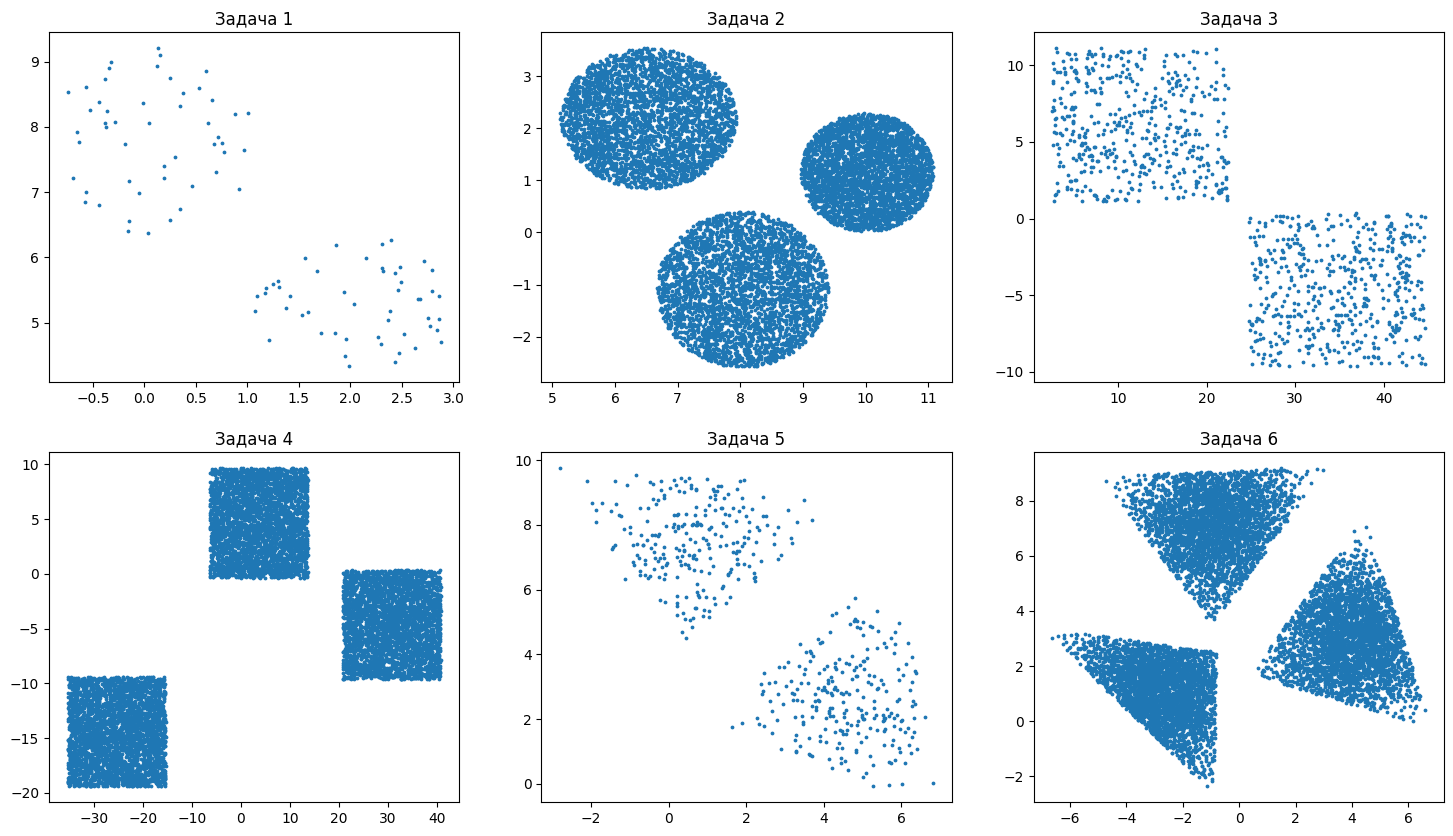

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, (P, ax) in enumerate(zip(data, axes.flat)):
    ax.scatter(P[:, 0], P[:, 1], s=3)
    ax.set_title(f'Задача {i+1}')
plt.show()

### 2. Кластеризация руками

In [17]:
def nearest(P, centers):
    return cdist(P, np.array(centers)).argmin(axis=1)

rules = [
    lambda P: (P[:, 1] > 6.35).astype(int),
    lambda P: nearest(P, [(6.5, 2.2), (8, -1), (10, 1.2)]),
    lambda P: (P[:, 1] > 0.7).astype(int),
    lambda P: np.where(P[:, 0] < -10, 0, np.where(P[:, 0] < 17, 1, 2)),
    lambda P: nearest(P, [(0, 7.5), (4.5, 2.5)]),
    lambda P: nearest(P, [(-0.3, 7), (-3, 0.8), (4, 3)]),
]
labels = [rule(P) for rule, P in zip(rules, data)]
for i, L in enumerate(labels):
    print(f'задача {i+1}: размеры кластеров {np.bincount(L)}')

задача 1: размеры кластеров [50 50]
задача 2: размеры кластеров [3333 3333 3333]
задача 3: размеры кластеров [524 476]
задача 4: размеры кластеров [3429 3284 3287]
задача 5: размеры кластеров [250 250]
задача 6: размеры кластеров [3333 3333 3333]


### 3. Распределение точек с раскраской по кластерам (медоиды отмечены крестом)

### 4. Медоид кластера

задача 1: медоиды [[2.0339, 5.2893], [0.0481, 8.0531]]
задача 2: медоиды [[6.47, 2.1698], [8.0401, -1.1087], [10.0225, 1.1542]]
задача 3: медоиды [[35.5162, -4.4498], [11.5036, 5.5592]]
задача 4: медоиды [[-25.1308, -14.4133], [3.5179, 4.6537], [30.8495, -4.5172]]
задача 5: медоиды [[0.6778, 7.4683], [4.4993, 2.5248]]
задача 6: медоиды [[-0.924, 7.1199], [-2.7497, 1.1431], [3.8586, 2.9072]]


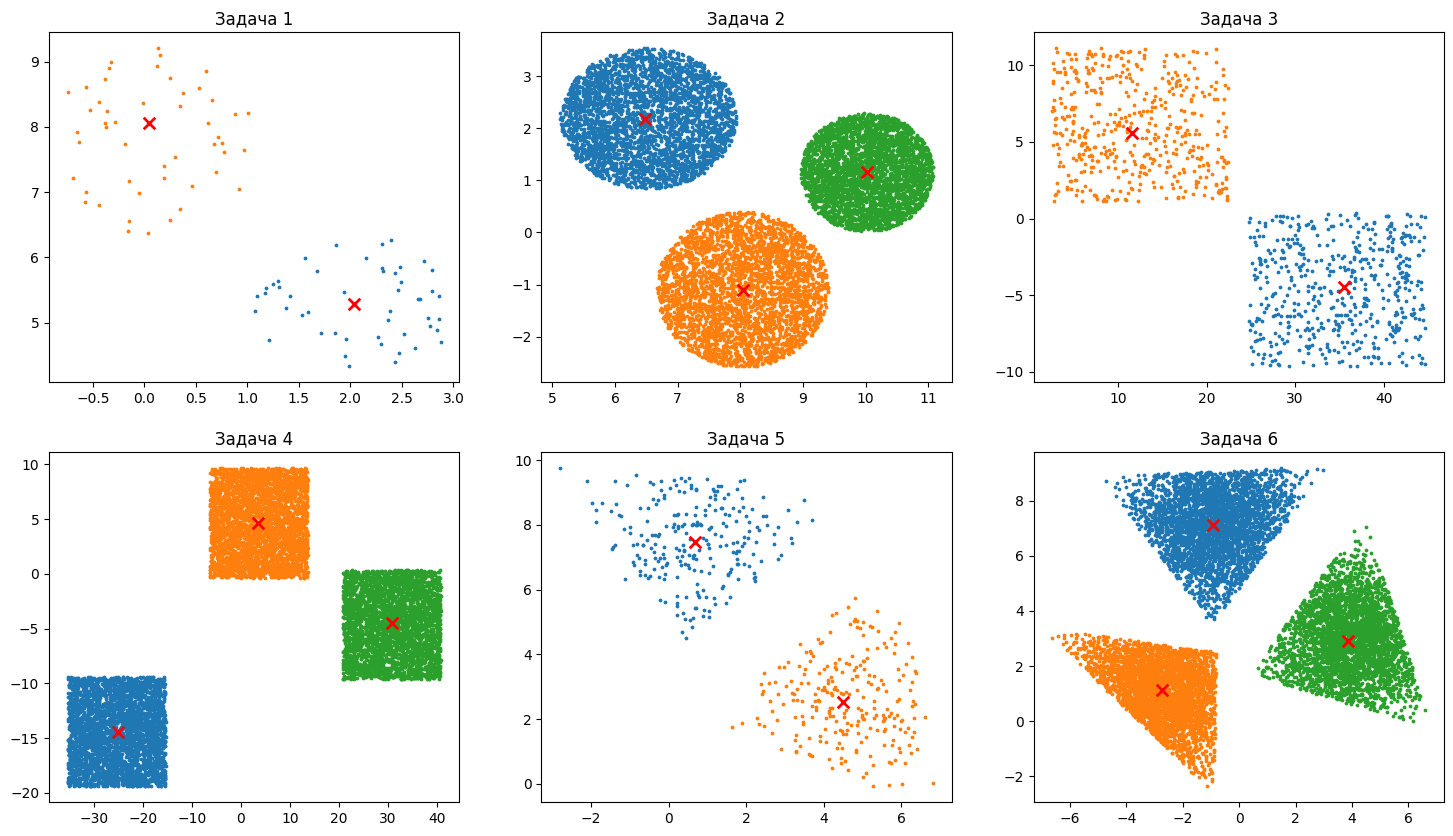

In [18]:
def medoid(P, metric):
    D = cdist(P, P, metric=metric)
    return P[D.sum(axis=1).argmin()]

palette = ['tab:blue', 'tab:orange', 'tab:green']
medoids = []
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, (P, L, ax) in enumerate(zip(data, labels, axes.flat)):
    ms = [medoid(P[L == k], metrics[i]) for k in range(L.max() + 1)]
    medoids.append(np.array(ms))
    for k in range(L.max() + 1):
        ax.scatter(P[L == k, 0], P[L == k, 1], s=3, color=palette[k])
    ms = np.array(ms)
    ax.scatter(ms[:, 0], ms[:, 1], marker='x', s=70, color='red', linewidths=2)
    ax.set_title(f'Задача {i+1}')
    print(f'задача {i+1}: медоиды', np.round(ms, 4).tolist())
plt.show()

### 5. Ответ: среднее центров кластеров × 1000 (целая часть)

In [19]:
for i, M in enumerate(medoids):
    Px, Py = M.mean(axis=0)
    print(f'задача {i+1}: Px = {Px*1000:.3f} -> {int(Px*1000)},  Py = {Py*1000:.3f} -> {int(Py*1000)}')

задача 1: Px = 1041.006 -> 1041,  Py = 6671.173 -> 6671
задача 2: Px = 8177.531 -> 8177,  Py = 738.419 -> 738
задача 3: Px = 23509.903 -> 23509,  Py = 554.682 -> 554
задача 4: Px = 3078.894 -> 3078,  Py = -4758.945 -> -4758
задача 5: Px = 2588.540 -> 2588,  Py = 4996.568 -> 4996
задача 6: Px = 61.652 -> 61,  Py = 3723.362 -> 3723


# Кластеризация (0.75 за каждый алгоритм на всех данных)

In [20]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

In [21]:
two_means = lambda p: cluster.MiniBatchKMeans(n_clusters=p["n_clusters"], n_init=3, random_state=0)
dbscan = lambda p: cluster.DBSCAN(eps=p["eps"], min_samples=p["min_samples"])

clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )

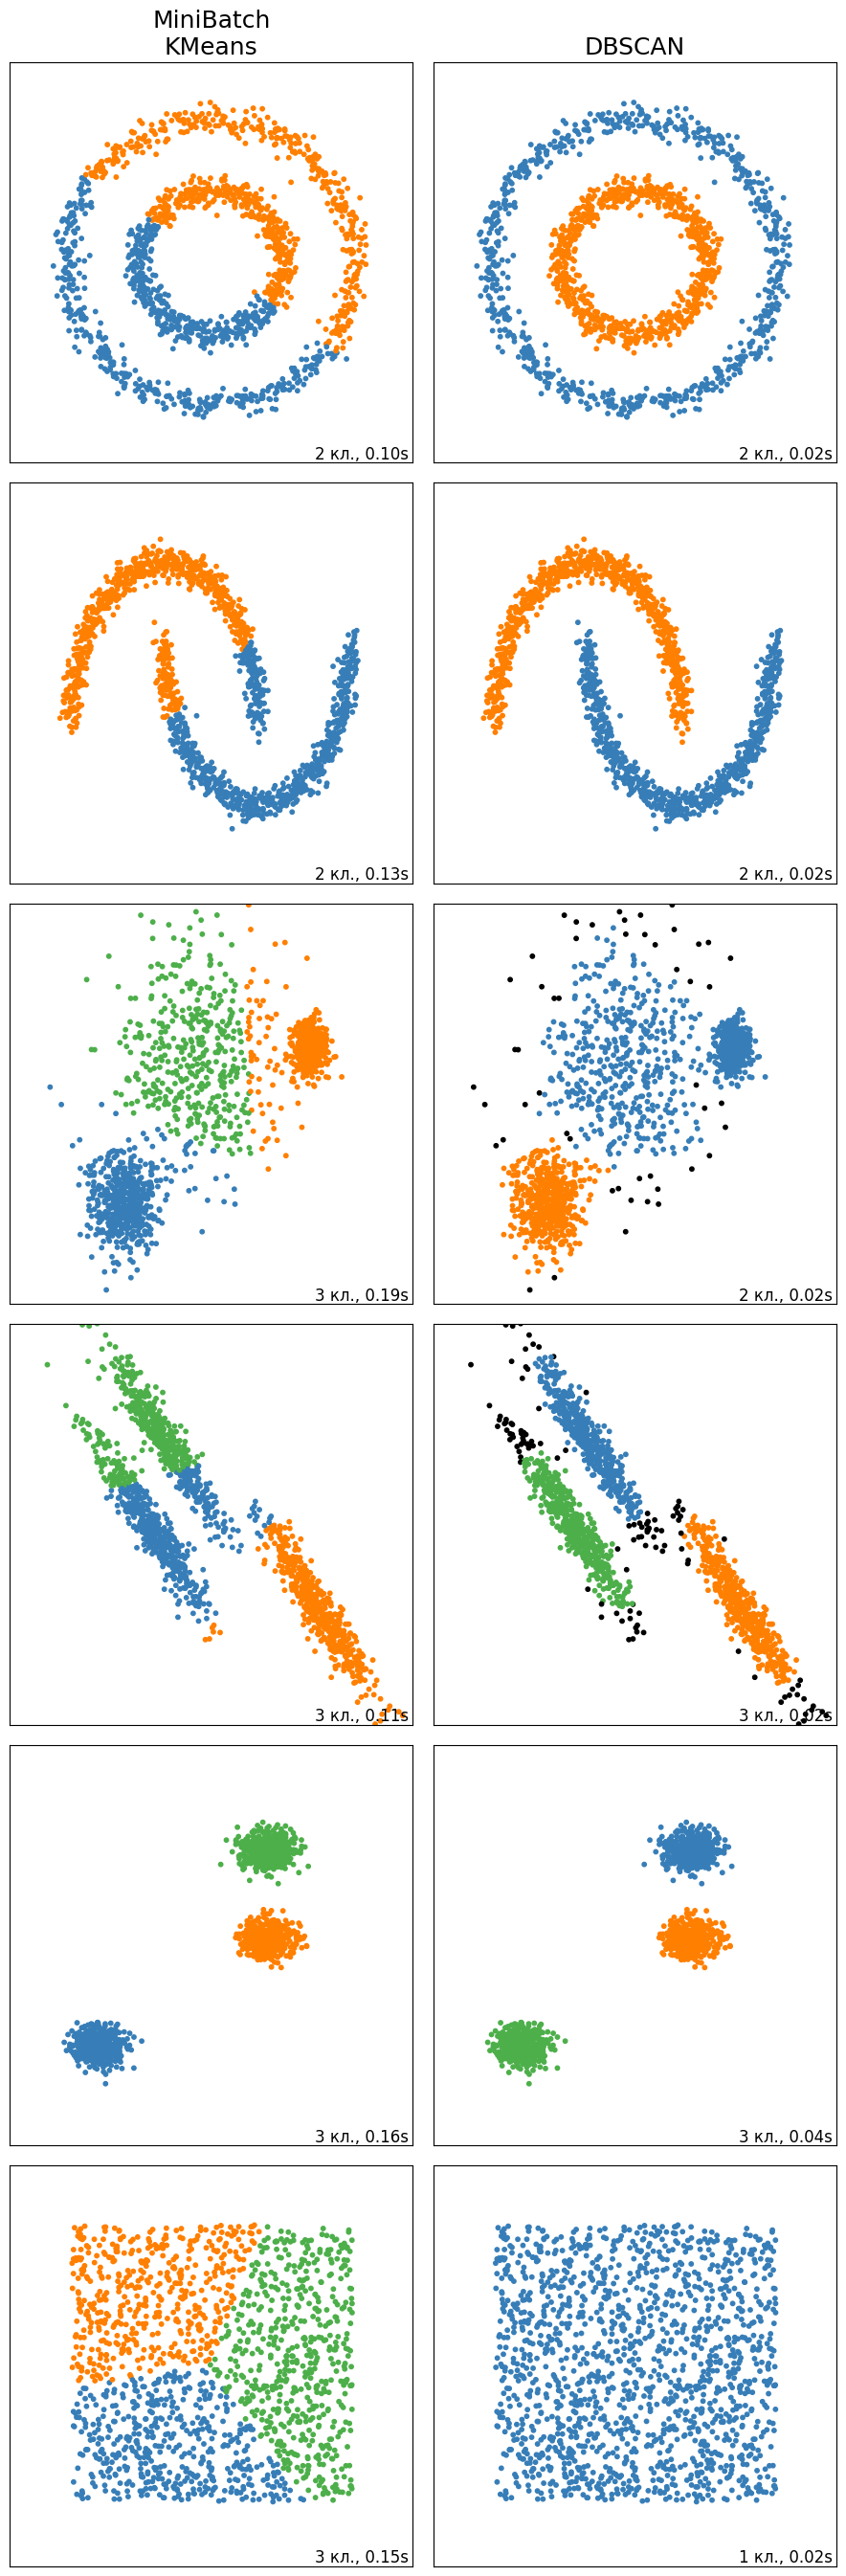

In [22]:
np.random.seed(0)

n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

plt.figure(figsize=(9, 27))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.97, wspace=0.05, hspace=0.05
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 5,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 20,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets):
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    X = StandardScaler().fit_transform(X)

    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    connectivity = 0.5 * (connectivity + connectivity.T)

    for name, algorithm in clustering_algorithms:
        t0 = time.time()
        algo = algorithm(params)
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="the number of connected components of the connectivity matrix")
            algo.fit(X)
        t1 = time.time()
        y_pred = algo.labels_.astype(int)

        plt.subplot(len(datasets), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=18)

        colors = np.array(list(islice(cycle(["#377eb8", "#ff7f00", "#4daf4a", "#f781bf",
                                             "#a65628", "#984ea3", "#999999", "#e41a1c", "#dede00"]),
                                      int(max(y_pred) + 1))))
        colors = np.append(colors, ["#000000"])
        plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[y_pred])
        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        plt.xticks(())
        plt.yticks(())
        n_cl = len(set(y_pred) - {-1})
        plt.text(0.99, 0.01, f"{n_cl} кл., {t1 - t0:.2f}s", transform=plt.gca().transAxes,
                 size=12, horizontalalignment="right")
        plot_num += 1

plt.show()
